# Experiment 4: combining neighbouring windows (temporal smoothing)

Same question and the same trained models as `experiment_zones.ipynb` and `experiment_zones_distance.ipynb` (three phones on the floor, which 50 cm zone is the speaker in?). Each model answers every 0.5 s from one 1 s window on its own. A person walks at about 0.4 m/s, so the zone hardly changes between neighbouring windows; this notebook asks **how much it helps to combine the model's answers over a few seconds, and how many seconds are needed**.

## What is swapped, what is the same
* **Swapped:** the answer for a window is no longer that window's own most probable zone. The zone probabilities of the windows within a span of time around it are combined first (mean of the log-probabilities), and the answer is the most probable zone of the combination.
* **Same as before:** the data, windows, split, zones and models. Nothing is retrained: the notebook reads the predictions the two zone notebooks saved (`*_probs.npz` in `trained_models_zones/` and `trained_models_zones_distance/`). It needs neither the WAVs nor torch, and runs in seconds.

## Two ways to combine
* **Centred (offline):** the windows before and after, symmetric around the window. Uses the future, so it fits analysis of a recording.
* **Causal (past only):** the window and the ones before it. Usable live, but it lags when the person moves.

A span of `S` seconds covers the windows whose 1 s extent lies inside it: `n = 2(S - 1) + 1` windows 0.5 s apart (3 s = 5 windows). Windows are only combined within one unbroken run of 0.5 s steps of the same session (the dataset drops windows with no position label, which leaves gaps).

## How the span is chosen
The span is a property of the **validation** windows (the last 20% of sessions 1 and 2, as in the zone notebooks). The sweep below prints, per model, the shortest span whose validation median is within 1 cm of its best. For one number to report for all models, **3 s** is used: for the two best models the validation curve is flat from 2 to 6 s (log-mel CNN) or within 2 cm of its best (8-band MLP). The sweep on session 3 is printed and drawn as well, labelled as such, to show the shape. Caution: 3 s was settled after session-3 numbers had been seen in an earlier quick look, so the strict per-model rule is reported next to it in the verdict.

## Main assumption
The recordings have **one person reading aloud the whole time**, so the neighbouring windows are the same speaker, speaking. With short utterances, silences or several people taking turns, the neighbours may hold other speakers or no speech, and combining them can hurt. That is not tested here.

In [5]:
import os
if not os.path.exists("/content/chatter"):
    !git clone -b feasibility-models https://github.com/ZiangXue/chatter.git /content/chatter
%cd /content/chatter/feasibility/experiment
!ls

/content/chatter/feasibility/experiment
experiment.ipynb		 trained_models
experiment_zones_distance.ipynb  trained_models_zones
experiment_zones.ipynb		 trained_models_zones_distance
temporal_results


In [6]:
from pathlib import Path
import csv, json

import numpy as np
import matplotlib.pyplot as plt

# ---- knobs ----
ZONE = 0.5            # m, zone size of the saved models
STEP_S = 0.5          # s between windows (as in the dataset)
SPANS_S = [1, 2, 3, 4, 5, 6, 8, 11, 16]   # spans to sweep; 1 s = one window = no smoothing
MAIN_SPAN_S = 3.0     # the one span reported for all models (validation curves flat around it; see the sweep)
TOL_CM = 1.0          # "within 1 cm of the best" for choosing the span on validation

DATA = Path("../presets/apartment/dataset")
MODEL_DIRS = {"cross-entropy": Path("trained_models_zones"), "expected distance": Path("trained_models_zones_distance")}
MODELS = {"8-band MLP": "8band_MLP_zone50cm", "log-mel CNN": "logmel_CNN_zone50cm", "raw-audio CNN": "rawaudio_CNN_zone50cm"}
OUT = Path("temporal_results"); OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
C_CENT, C_CAUS, C_NONE, C_TRUE = "#2a78d6", "#e07a1f", "#9aa0a8", "#16202e"

## Data: the window list and its labels (rebuilt without the audio)
The saved predictions are indexed by window number in the dataset's order. That order is rebuilt here from `positions.csv` and `meta.json` with the same rules as `WindowedSessions` in the zone notebooks (1 s windows, 0.5 s step, starting at `usable_from_s`, a window kept only if a position sample lies within 0.15 s of its centre, label = the position interpolated at the centre). The check against the zone notebooks' window counts (1001 / 1136 / 826) makes sure the order is the same.

In [7]:
rows = []                                         # (session, centre time s, seconds since the last start clap, x m, y m)
for n in (1, 2, 3):
    d = DATA / f"session{n}"; meta = json.load(open(d / "meta.json"))
    sr = 16000; W, S = sr, sr // 2
    n_samples = int(np.ceil(meta["n_samples"] * sr / meta["sample_rate"]))
    pos = [r for r in csv.DictReader(open(d / "positions.csv")) if r["x_m"] != ""]
    t = np.array([float(r["t_audio_s"]) for r in pos]); xy = np.array([[float(r["x_m"]), float(r["y_m"])] for r in pos])
    for st in range(round(meta["usable_from_s"] * sr), n_samples - W + 1, S):
        tc = (st + W / 2) / sr; k = np.searchsorted(t, tc)
        if min((abs(t[j] - tc) for j in (k - 1, k) if 0 <= j < len(t)), default=np.inf) > 0.15:
            continue
        rows.append((n, tc, tc - meta["claps_t_audio_s"][-1], np.interp(tc, t, xy[:, 0]), np.interp(tc, t, xy[:, 1])))

sess = np.array([r[0] for r in rows]); t_centre = np.array([r[1] for r in rows])
t_clap = np.array([r[2] for r in rows]); truth = np.array([r[3:] for r in rows])
counts = [int((sess == n).sum()) for n in (1, 2, 3)]
assert counts == [1001, 1136, 826], counts
print("windows per session:", counts, "(same as the zone notebooks)")

windows per session: [1001, 1136, 826] (same as the zone notebooks)


## The saved predictions
For every model, each `*_probs.npz` holds the zone probabilities on the validation windows (model trained on the first 80% of sessions 1 and 2) and on the test windows (model refit on all of sessions 1 and 2), with the window indices and the zone keys of the output columns. Six models: three inputs × two losses.

In [8]:
runs = {}
for loss, folder in MODEL_DIRS.items():
    for name, tag in MODELS.items():
        z = np.load(folder / f"{tag}_probs.npz")
        runs[(name, loss)] = dict(val_idx=z["val_idx"], test_idx=z["test_idx"], p_val=z["probs_val"], p_test=z["probs_test"],
                                  keys_val=z["classes_tr"], keys_test=z["classes_fit"])
te_idx = runs[("log-mel CNN", "cross-entropy")]["test_idx"]; va_idx = runs[("log-mel CNN", "cross-entropy")]["val_idx"]
assert all((r["test_idx"] == te_idx).all() and (r["val_idx"] == va_idx).all() for r in runs.values())
print(f"{len(runs)} models; {len(va_idx)} validation windows, {len(te_idx)} test windows (session 3)")

6 models; 427 validation windows, 826 test windows (session 3)


## Combining neighbouring windows
`combine` averages the log-probabilities of the windows inside the span (only windows of the same unbroken run) and `score` turns the result into a zone, measured the same way as in the zone notebooks: the distance from the **centre of the chosen zone** to the true position, and whether the zone is the true one or one of its 8 neighbours.

In [9]:
def n_windows(span_s):
    return int(round((span_s - 1) / STEP_S)) + 1        # 1 s -> 1, 2 s -> 3, 3 s -> 5, ...

def runs_of(idx):
    # an id per unbroken run of 0.5 s steps within one session
    br = (np.diff(t_centre[idx]) > STEP_S + 0.01) | (np.diff(sess[idx]) != 0)
    return np.concatenate([[0], np.cumsum(br)])

def combine(probs, idx, span_s, causal):
    lp = np.log(probs + 1e-9); n = n_windows(span_s); run = runs_of(idx); out = np.empty_like(lp)
    for i in range(len(idx)):
        lo, hi = (i - n + 1, i + 1) if causal else (i - (n - 1) // 2, i + (n - 1) // 2 + 1)
        j = np.arange(max(lo, 0), min(hi, len(idx))); j = j[run[j] == run[i]]
        out[i] = lp[j].mean(0)
    return out

def score(scores, keys, idx):
    k_pred = keys[scores.argmax(1)]; k_true = np.floor(truth[idx] / ZONE + 1e-9).astype(int)
    d = np.linalg.norm((k_pred + 0.5) * ZONE - truth[idx], axis=1) * 100
    cheb = np.abs(k_pred - k_true).max(1)
    return dict(median=np.median(d), p90=np.percentile(d, 90), exact=(cheb == 0).mean(), within1=(cheb <= 1).mean(),
                d=d, pred=(k_pred + 0.5) * ZONE)

## How long a span? (chosen on validation)
Median distance against the span, for the two lighter models with cross-entropy (the other runs follow the same shape; their numbers are in the table further down). Solid: validation, which picks the span; dashed: session 3, shown for the shape only.

model                             mode          1 s    2 s    3 s    4 s    5 s    6 s    8 s   11 s   16 s   chosen on val
8-band MLP (cross-entropy)        centred val     41     37     35     33     34     34     35     34     34   4 s
8-band MLP (cross-entropy)        centred test     60     54     50     50     47     46     47     50     56   
8-band MLP (cross-entropy)        causal val     41     38     37     36     37     37     40     43     48   4 s
8-band MLP (cross-entropy)        causal test     60     55     52     52     52     54     57     65     72   
log-mel CNN (cross-entropy)       centred val     37     32     31     31     31     31     32     32     33   2 s
log-mel CNN (cross-entropy)       centred test     49     45     42     42     42     42     45     48     49   
log-mel CNN (cross-entropy)       causal val     37     33     32     32     32     33     40     45     50   2 s
log-mel CNN (cross-entropy)       causal test     49     46     46     47     49

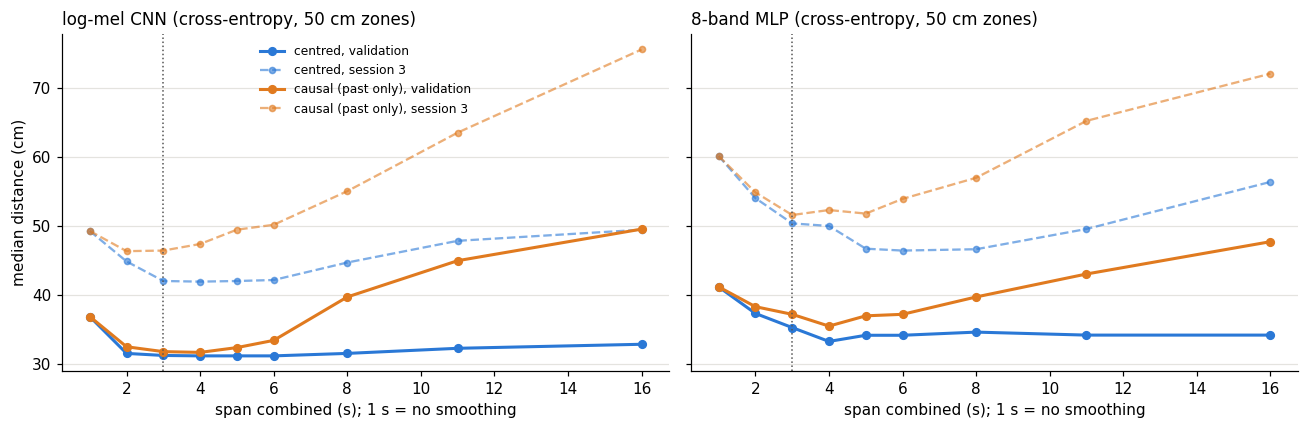

In [10]:
sweep = {}
for (name, loss), r in runs.items():
    for causal in (False, True):
        for span in SPANS_S:
            sweep[(name, loss, causal, span, "val")] = score(combine(r["p_val"], va_idx, span, causal), r["keys_val"], va_idx)["median"]
            sweep[(name, loss, causal, span, "test")] = score(combine(r["p_test"], te_idx, span, causal), r["keys_test"], te_idx)["median"]

def chosen_span(name, loss, causal):
    v = {s: sweep[(name, loss, causal, s, "val")] for s in SPANS_S}
    best = min(v.values())
    return min(s for s in SPANS_S if v[s] <= best + TOL_CM)

print(f"{'model':<34}{'mode':<10}" + "".join(f"{str(s) + ' s':>7}" for s in SPANS_S) + "   chosen on val")
for (name, loss) in runs:
    for causal in (False, True):
        for split in ("val", "test"):
            vals = "".join(f"{sweep[(name, loss, causal, s, split)]:7.0f}" for s in SPANS_S)
            tag = f"{chosen_span(name, loss, causal)} s" if split == "val" else ""
            print(f"{name + ' (' + loss + ')':<34}{('causal' if causal else 'centred') + ' ' + split:<10}{vals}   {tag}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, ("log-mel CNN", "8-band MLP")):
    for causal, col, lab in ((False, C_CENT, "centred"), (True, C_CAUS, "causal (past only)")):
        ax.plot(SPANS_S, [sweep[(name, "cross-entropy", causal, s, "val")] for s in SPANS_S], "o-", color=col, lw=2, ms=5, label=f"{lab}, validation")
        ax.plot(SPANS_S, [sweep[(name, "cross-entropy", causal, s, "test")] for s in SPANS_S], "o--", color=col, lw=1.5, ms=4, alpha=0.6, label=f"{lab}, session 3")
    ax.axvline(MAIN_SPAN_S, color="#555", lw=1, ls=":")
    ax.set_title(f"{name} (cross-entropy, 50 cm zones)", loc="left", fontsize=11)
    ax.set_xlabel("span combined (s); 1 s = no smoothing"); ax.grid(axis="y", color="#e4e3df")
axes[0].set_ylabel("median distance (cm)"); axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(OUT / "span_sweep.png", dpi=150); plt.show()

## Results at 3 s
All six models, no smoothing against a 3 s span (centred and causal). The rough-guess baseline is the majority zone of sessions 1+2, as in the zone notebooks.

In [11]:
fit = np.where(sess != 3)[0]
k_fit, c_fit = np.unique(np.floor(truth[fit] / ZONE + 1e-9).astype(int), axis=0, return_counts=True)
maj = (k_fit[c_fit.argmax()] + 0.5) * ZONE
d_maj = np.linalg.norm(maj - truth[te_idx], axis=1) * 100
cheb_maj = np.abs(k_fit[c_fit.argmax()] - np.floor(truth[te_idx] / ZONE + 1e-9).astype(int)).max(1)

results = {}
hdr = f"{'model':<34}{'smoothing':<16}{'median':>8}{'p90':>7}{'exact':>8}{'within 1':>10}"
print(hdr + "   (session 3, 826 windows; distances in cm)")
print(f"{'majority zone (baseline)':<34}{'-':<16}{np.median(d_maj):8.0f}{np.percentile(d_maj, 90):7.0f}{(cheb_maj == 0).mean():8.1%}{(cheb_maj <= 1).mean():10.1%}")
for (name, loss), r in runs.items():
    for label, span, causal in (("none", 1, False), ("3 s centred", MAIN_SPAN_S, False), ("3 s causal", MAIN_SPAN_S, True)):
        s = score(combine(r["p_test"], te_idx, span, causal), r["keys_test"], te_idx)
        results[(name, loss, label)] = s
        print(f"{name + ' (' + loss + ')':<34}{label:<16}{s['median']:8.0f}{s['p90']:7.0f}{s['exact']:8.1%}{s['within1']:10.1%}")
    print()

model                             smoothing         median    p90   exact  within 1   (session 3, 826 windows; distances in cm)
majority zone (baseline)          -                    118    167    3.6%     23.0%
8-band MLP (cross-entropy)        none                  60    147   21.4%     65.6%
8-band MLP (cross-entropy)        3 s centred           50    134   27.5%     72.3%
8-band MLP (cross-entropy)        3 s causal            52    134   24.2%     72.4%

log-mel CNN (cross-entropy)       none                  49    135   26.8%     74.3%
log-mel CNN (cross-entropy)       3 s centred           42    122   32.1%     79.7%
log-mel CNN (cross-entropy)       3 s causal            46    115   26.9%     80.0%

raw-audio CNN (cross-entropy)     none                  69    162   14.8%     58.0%
raw-audio CNN (cross-entropy)     3 s centred           65    155   17.9%     62.7%
raw-audio CNN (cross-entropy)     3 s causal            65    146   17.6%     64.5%

8-band MLP (expected distance

### The track of the headline model
Log-mel CNN (cross-entropy) on session 3: the true position, the zone centre it picks on its own, and with the 3 s centred span. Single-window jumps to far zones are mostly removed; long stretches where the model is consistently wrong stay wrong, most visibly in y below -0.35 m (the front of the room, never walked in sessions 1+2), where it keeps answering the nearest zone it knows.

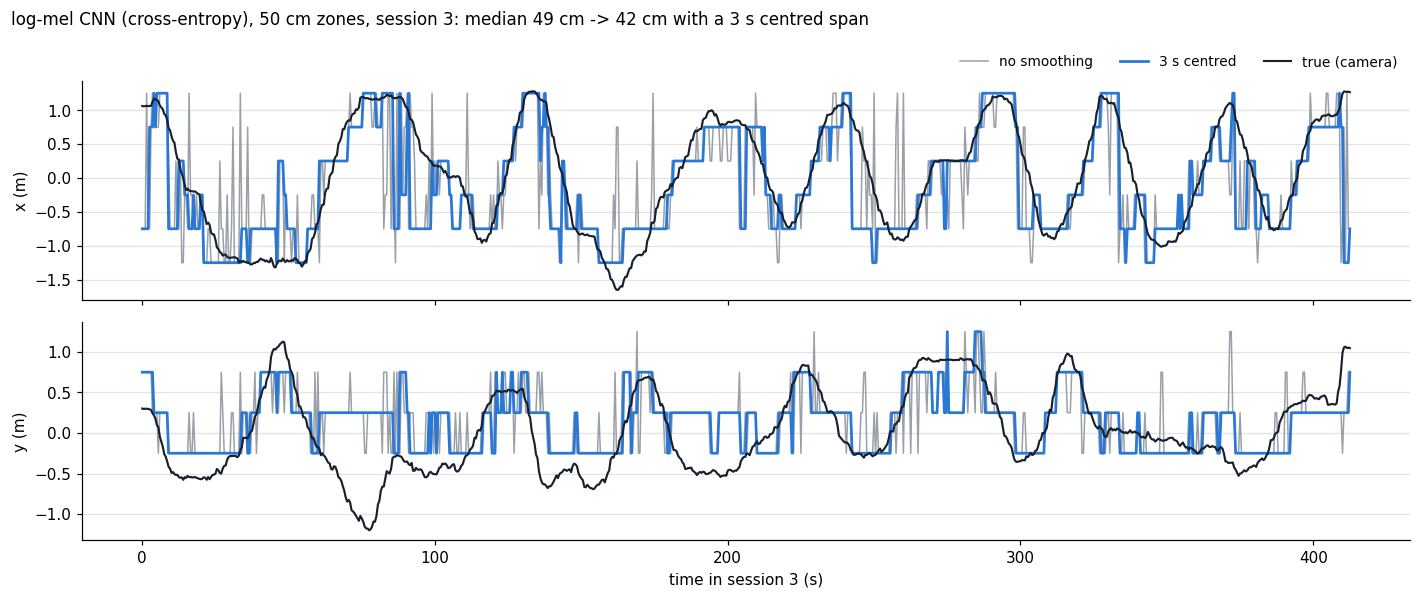

In [12]:
name, loss = "log-mel CNN", "cross-entropy"
raw, cen = results[(name, loss, "none")], results[(name, loss, "3 s centred")]
tt = t_centre[te_idx] - t_centre[te_idx][0]
fig, axes = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
for ax, a, lab in zip(axes, (0, 1), ("x (m)", "y (m)")):
    ax.plot(tt, raw["pred"][:, a], color=C_NONE, lw=1, label="no smoothing")
    ax.plot(tt, cen["pred"][:, a], color=C_CENT, lw=1.8, label="3 s centred")
    ax.plot(tt, truth[te_idx][:, a], color=C_TRUE, lw=1.4, label="true (camera)")
    ax.set_ylabel(lab); ax.grid(axis="y", color="#e4e3df")
axes[0].legend(ncol=3, fontsize=9, frameon=False, loc="lower right", bbox_to_anchor=(1, 1.0))
axes[1].set_xlabel("time in session 3 (s)")
fig.suptitle(f"{name} ({loss}), 50 cm zones, session 3: median {raw['median']:.0f} cm -> {cen['median']:.0f} cm with a 3 s centred span", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.savefig(OUT / "track_session3.png", dpi=150); plt.show()

## Extra checks: per axis, familiar against new ground, and over time
On the same saved predictions (no smoothing, and the headline model with 3 s). "Inside" means inside the bounding box walked in sessions 1+2, as in `experiment.ipynb`. "Over time" bins the windows by minutes since the last start clap: clock drift, not corrected in the dataset, grows with that time.

In [13]:
lo, hi = truth[fit].min(0), truth[fit].max(0)
inside = ((truth[te_idx] >= lo) & (truth[te_idx] <= hi)).all(1)
print(f"session 3: {inside.sum()} of {len(te_idx)} windows ({inside.mean():.0%}) inside the box walked in sessions 1+2 "
      f"(x {lo[0]:.2f}..{hi[0]:.2f} m, y {lo[1]:.2f}..{hi[1]:.2f} m)\n")
print(f"{'':<46}{'median':>8}{'inside':>8}{'outside':>9}{'|x| in':>8}{'|y| in':>8}{'|x| out':>9}{'|y| out':>9}   (cm, medians)")
def row(label, pred):
    e = np.abs(pred - truth[te_idx]) * 100; d = np.linalg.norm(pred - truth[te_idx], axis=1) * 100
    print(f"{label:<46}{np.median(d):8.0f}{np.median(d[inside]):8.0f}{np.median(d[~inside]):9.0f}"
          f"{np.median(e[inside, 0]):8.0f}{np.median(e[inside, 1]):8.0f}{np.median(e[~inside, 0]):9.0f}{np.median(e[~inside, 1]):9.0f}")
row("majority zone (baseline)", np.tile(maj, (len(te_idx), 1)))
for (name, loss) in runs:
    row(f"{name} ({loss})", results[(name, loss, "none")]["pred"])
row("log-mel CNN (cross-entropy), 3 s centred", results[("log-mel CNN", "cross-entropy", "3 s centred")]["pred"])

print("\nmedian distance (cm) by minutes since the last start clap, session 3, log-mel CNN (cross-entropy), no smoothing")
m = (t_clap[te_idx] // 60).astype(int); d = results[("log-mel CNN", "cross-entropy", "none")]["d"]
print("  minute    " + "".join(f"{k:>6}" for k in range(m.max() + 1)))
print("  model     " + "".join(f"{np.median(d[m == k]):6.0f}" for k in range(m.max() + 1)))
print("  baseline  " + "".join(f"{np.median(d_maj[m == k]):6.0f}" for k in range(m.max() + 1)))
print("  ratio     " + "".join(f"{np.median(d[m == k]) / np.median(d_maj[m == k]):6.2f}" for k in range(m.max() + 1)))

session 3: 579 of 826 windows (70%) inside the box walked in sessions 1+2 (x -1.51..1.50 m, y -0.35..1.26 m)

                                                median  inside  outside  |x| in  |y| in  |x| out  |y| out   (cm, medians)
majority zone (baseline)                           118     101      153      65      58       84      124
8-band MLP (cross-entropy)                          60      51       86      23      28       36       68
log-mel CNN (cross-entropy)                         49      40       77      23      20       34       44
raw-audio CNN (cross-entropy)                       69      53      103      39      26       55       71
8-band MLP (expected distance)                      61      50       91      24      30       41       74
log-mel CNN (expected distance)                     50      45       73      23      24       24       64
raw-audio CNN (expected distance)                   81      59      116      44      33       43       82
log-mel CNN (cross-entropy

# Verdict
*One test session; differences of a few cm or a few percentage points are noise.*

**1. Combining a few seconds of answers helps clearly, for the two spectral models.** With a 3 s centred span the log-mel CNN (cross-entropy) goes from 49 to **42 cm** median, 26.8% → 32.1% exact zone and 74% → 80% within one cell; the 8-band MLP from 60 to 50 cm. Past-only (usable live): 46 cm and 52 cm. With the strict per-model rule on validation (shortest span within 1 cm of the best) the log-mel CNN would get 2 s and 45 / 46 cm (centred / causal), and the 8-band MLP 4 s and 50 / 52 cm: the gain does not depend on the exact span.

**2. About 2–3 s is enough; longer spans stop helping or hurt.** On validation the log-mel CNN is flat from 2 to 6 s centred. Past-only gets worse beyond about 4 s, because the answer lags when the person walks (session 3: 46 cm at 2–3 s, 55 cm at 8 s, 76 cm at 16 s).

**3. Time context gave more than finer frequency detail.** The plain 8-band MLP with 3–5 s of context (47–50 cm) matches the log-mel CNN on one window (49 cm). Both together are best (42 cm).

**4. The raw-audio CNN gains little** (69 → 65 cm): its errors are mostly systematic, not single-window jumps, so averaging does not remove them. The same holds for the ground not walked in training: smoothing lowers the error inside the walked box (40 → 33 cm, x and y both ~18 cm) much more than outside it (77 → 72 cm).

**5. No sign of the error growing with time since the claps** (model / baseline ratio 0.3–0.6 over the whole session, no trend), as expected for features that ignore the phase.

## What this does not show
* It assumes one person speaking continuously, as in the recordings. Short utterances, pauses and turn-taking between several people would mix other speakers or silence into the span; the next step there is to combine only windows of the same speaker, and to weight windows by how much speech they hold.
* The span was settled with session-3 numbers already seen; the per-model rule above gives nearly the same result, but a new session would confirm it.
* Comparing with longer **input** windows (2–4 s fed to the model instead of combining 1 s answers) needs retraining and is not done here.

## Files written
* `temporal_results/span_sweep.png`: median distance against the span (validation and session 3)
* `temporal_results/track_session3.png`: the headline model's track on session 3, with and without the 3 s span
* `temporal_results/summary.json`: the numbers of the 3 s table

In [14]:
summary = {f"{n} | {l} | {lab}": {k: float(v) for k, v in s.items() if k in ("median", "p90", "exact", "within1")}
           for (n, l, lab), s in results.items()}
summary["majority zone (baseline)"] = {"median": float(np.median(d_maj)), "p90": float(np.percentile(d_maj, 90)),
                                       "exact": float((cheb_maj == 0).mean()), "within1": float((cheb_maj <= 1).mean())}
json.dump(summary, open(OUT / "summary.json", "w"), indent=1)
print(sorted(p.name for p in OUT.iterdir()))

['span_sweep.png', 'summary.json', 'track_session3.png']
